# 01. Phân Tích Phổ Fourier Nhanh (FFT) Trên Tín Hiệu Y Sinh
### Fast Fourier Transform & Power Spectral Density Analysis on WESAD S1 (ECG, PPG, EMG)
**Tác giả:** Antigravity AI Assistant & Biomedical Signal DSP Specialist  
**Mục tiêu:**
1. Khám phá miền tần số của các tín hiệu y sinh thực tế (ECG, PPG, EMG) từ bộ dữ liệu **WESAD Subject S1**.
2. Tìm hiểu ảnh hưởng của rò rỉ phổ (*Spectral Leakage*) và các hàm cửa sổ (*Windowing: Hann, Hamming, Rectangular*).
3. Đánh giá can nhiễu điện lưới 50 Hz trên ECG/EMG và ước lượng dải tần sinh lý chủ đạo.


In [1]:
import os
import pickle
import numpy as np
import matplotlib.pyplot as plt
import scipy.signal as signal

# Cấu hình hiển thị đồ thị chuẩn
plt.style.use('default')
plt.rcParams.update({
    'font.family': 'serif',
    'font.size': 10,
    'axes.labelsize': 10,
    'axes.titlesize': 11,
    'axes.titleweight': 'bold',
    'figure.dpi': 130
})

DATA_PATH = r"e:\Study\S1\S1.pkl"
print(f"Loading WESAD S1 data from: {DATA_PATH}")
with open(DATA_PATH, "rb") as f:
    s1_data = pickle.load(f, encoding="latin1")

# Trích xuất các kênh tín hiệu chính
ecg_raw = s1_data['signal']['chest']['ECG'].flatten()
emg_raw = s1_data['signal']['chest']['EMG'].flatten()
bvp_raw = s1_data['signal']['wrist']['BVP'].flatten()

fs_chest = 700.0  # Hz (ECG, EMG)
fs_wrist = 64.0   # Hz (PPG/BVP)

print(f"ECG samples: {len(ecg_raw):,} (Fs = {fs_chest} Hz)")
print(f"EMG samples: {len(emg_raw):,} (Fs = {fs_chest} Hz)")
print(f"PPG samples: {len(bvp_raw):,} (Fs = {fs_wrist} Hz)")


Loading WESAD S1 data from: e:\Study\S1\S1.pkl


ECG samples: 6,448,400 (Fs = 700.0 Hz)
EMG samples: 6,448,400 (Fs = 700.0 Hz)
PPG samples: 589,568 (Fs = 64.0 Hz)


## 1. Trích xuất cửa sổ tín hiệu đại diện
Chúng ta chọn cửa sổ 10 giây ở trạng thái nghỉ ổn định (Baseline: giây 120 đến 130).


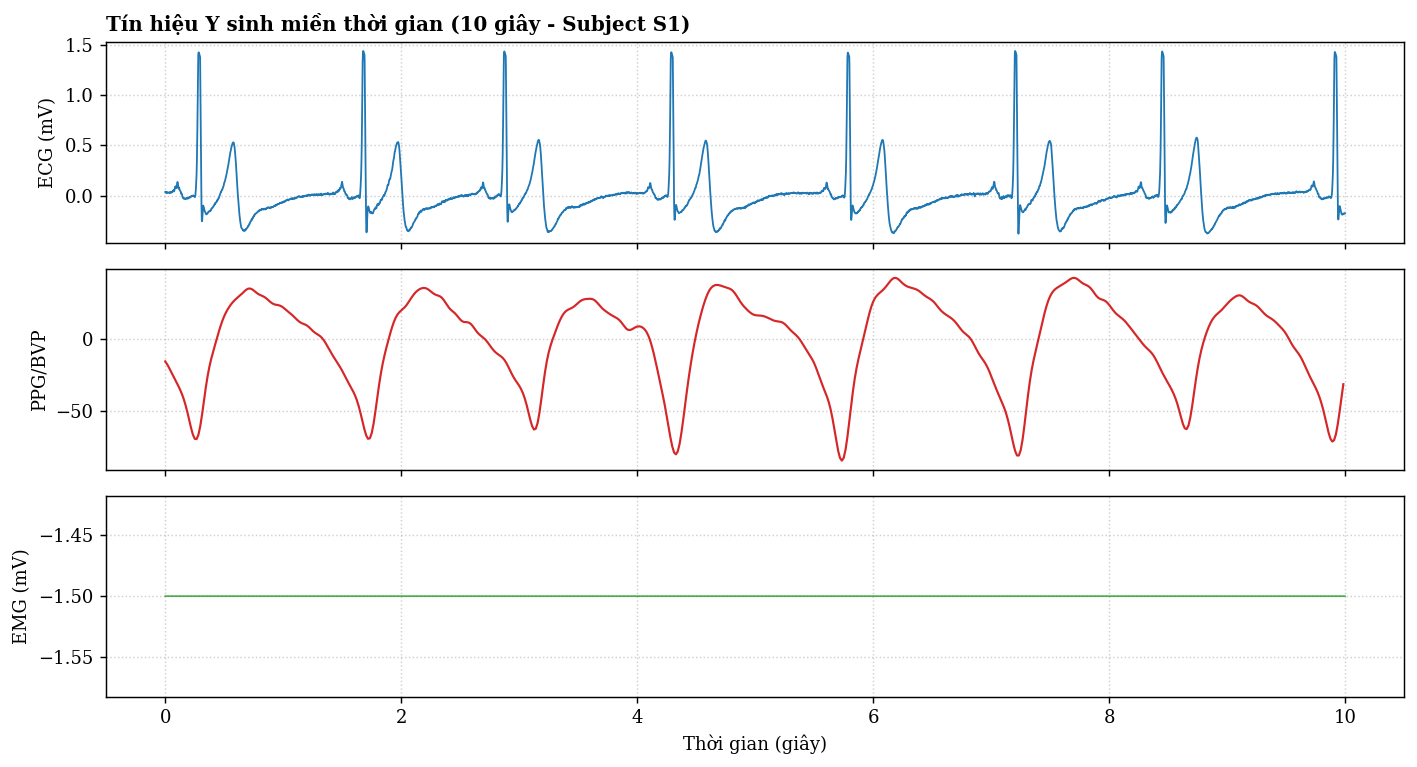

In [2]:
t_start_sec = 120.0
win_sec = 10.0

idx_ecg_start = int(t_start_sec * fs_chest)
idx_ecg_end = idx_ecg_start + int(win_sec * fs_chest)

idx_bvp_start = int(t_start_sec * fs_wrist)
idx_bvp_end = idx_bvp_start + int(win_sec * fs_wrist)

t_ecg = np.linspace(0, win_sec, idx_ecg_end - idx_ecg_start, endpoint=False)
t_bvp = np.linspace(0, win_sec, idx_bvp_end - idx_bvp_start, endpoint=False)

ecg_seg = ecg_raw[idx_ecg_start:idx_ecg_end]
emg_seg = emg_raw[idx_ecg_start:idx_ecg_end]
bvp_seg = bvp_raw[idx_bvp_start:idx_bvp_end]

fig, axes = plt.subplots(3, 1, figsize=(11, 6), sharex=True)
axes[0].plot(t_ecg, ecg_seg, color='#1f77b4', lw=1.0)
axes[0].set_ylabel('ECG (mV)')
axes[0].set_title('Tín hiệu Y sinh miền thời gian (10 giây - Subject S1)', loc='left')

axes[1].plot(t_bvp, bvp_seg, color='#d62728', lw=1.2)
axes[1].set_ylabel('PPG/BVP')

axes[2].plot(t_ecg, emg_seg, color='#2ca02c', lw=0.8)
axes[2].set_ylabel('EMG (mV)')
axes[2].set_xlabel('Thời gian (giây)')

for ax in axes:
    ax.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()


## 2. Phân tích Phổ FFT & Khảo sát Cửa sổ hoá (Windowing)
Khảo sát sự khác biệt giữa việc tính FFT trực tiếp (cửa sổ chữ nhật - Rectangular) và việc dùng cửa sổ Hann để triệt tiêu hiện tượng rò rỉ phổ (*Spectral Leakage*).


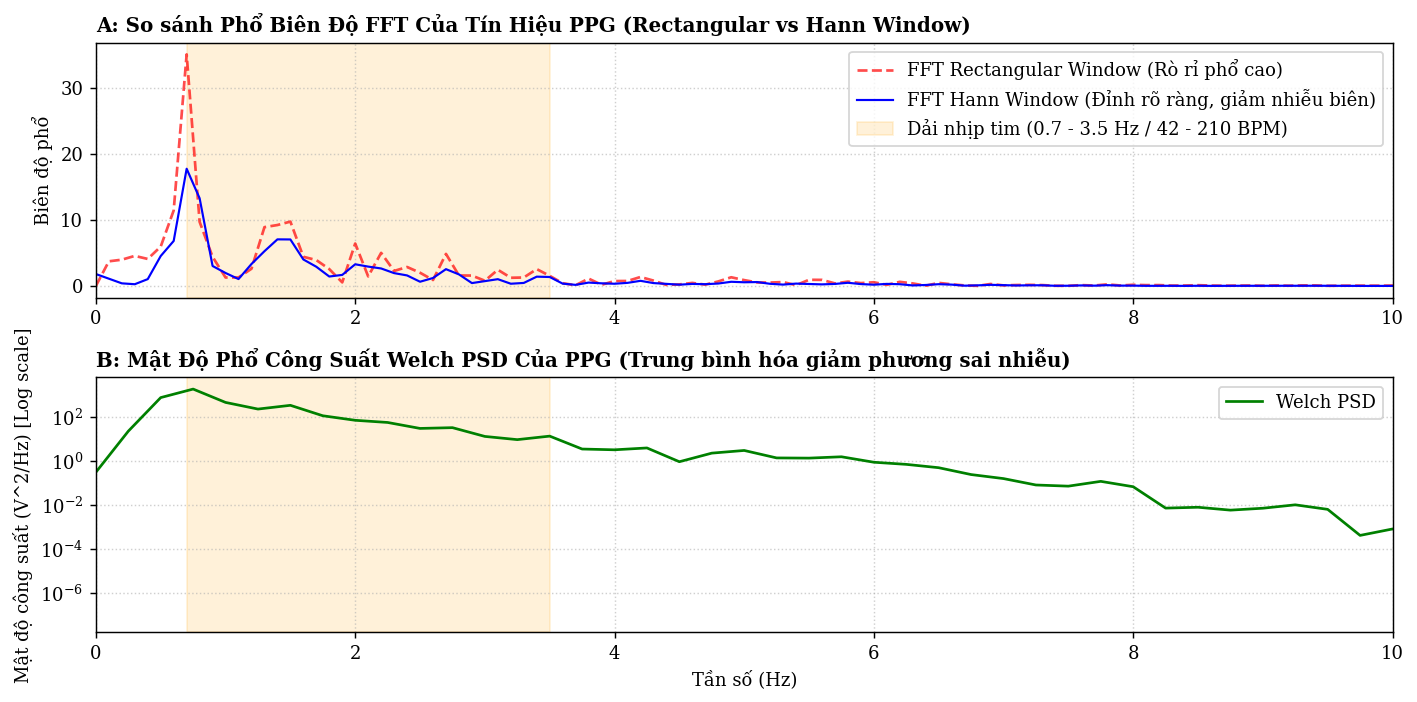

=> Tần số đỉnh nhịp mạch: 0.70 Hz -> Nhịp tim ước lượng: 42.0 BPM


In [3]:
# 1. FFT trên BVP (PPG)
N_bvp = len(bvp_seg)
bvp_detrend = bvp_seg - np.mean(bvp_seg)

# Cửa sổ chữ nhật (Rectangular) vs Cửa sổ Hann
fft_rect = np.fft.rfft(bvp_detrend)
fft_hann = np.fft.rfft(bvp_detrend * signal.windows.hann(N_bvp))
freqs_bvp = np.fft.rfftfreq(N_bvp, d=1.0/fs_wrist)

mag_rect = 2.0 / N_bvp * np.abs(fft_rect)
mag_hann = 2.0 / N_bvp * np.abs(fft_hann)

# 2. Welch PSD trên BVP
f_welch, p_welch = signal.welch(bvp_detrend, fs=fs_wrist, nperseg=int(4.0*fs_wrist))

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 5.5))
ax1.plot(freqs_bvp, mag_rect, 'r--', label='FFT Rectangular Window (Rò rỉ phổ cao)', alpha=0.7)
ax1.plot(freqs_bvp, mag_hann, 'b-', label='FFT Hann Window (Đỉnh rõ ràng, giảm nhiễu biên)', lw=1.2)
ax1.axvspan(0.7, 3.5, color='orange', alpha=0.15, label='Dải nhịp tim (0.7 - 3.5 Hz / 42 - 210 BPM)')
ax1.set_xlim([0, 10])
ax1.set_ylabel('Biên độ phổ')
ax1.set_title('A: So sánh Phổ Biên Độ FFT Của Tín Hiệu PPG (Rectangular vs Hann Window)', loc='left')
ax1.legend(loc='upper right')
ax1.grid(True, linestyle=':', alpha=0.6)

ax2.semilogy(f_welch, p_welch, 'g-', lw=1.5, label='Welch PSD')
ax2.axvspan(0.7, 3.5, color='orange', alpha=0.15)
ax2.set_xlim([0, 10])
ax2.set_xlabel('Tần số (Hz)')
ax2.set_ylabel('Mật độ công suất (V^2/Hz) [Log scale]')
ax2.set_title('B: Mật Độ Phổ Công Suất Welch PSD Của PPG (Trung bình hóa giảm phương sai nhiễu)', loc='left')
ax2.legend(loc='upper right')
ax2.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

# Xác định đỉnh nhịp tim
peak_idx = np.argmax(mag_hann[(freqs_bvp >= 0.7) & (freqs_bvp <= 3.5)])
peak_freq = freqs_bvp[(freqs_bvp >= 0.7) & (freqs_bvp <= 3.5)][peak_idx]
print(f"=> Tần số đỉnh nhịp mạch: {peak_freq:.2f} Hz -> Nhịp tim ước lượng: {peak_freq * 60.0:.1f} BPM")


## 3. Phân tích Phổ ECG và Can Nhiễu Điện Lưới 50 Hz
Tín hiệu ngực ECG (Fs = 700 Hz) cho phép phân tích dải tần lên tới 350 Hz (tần số Nyquist). Chúng ta khảo sát phổ công suất toàn dải để phát hiện nhiễu tần số công nghiệp (50 Hz / 60 Hz).


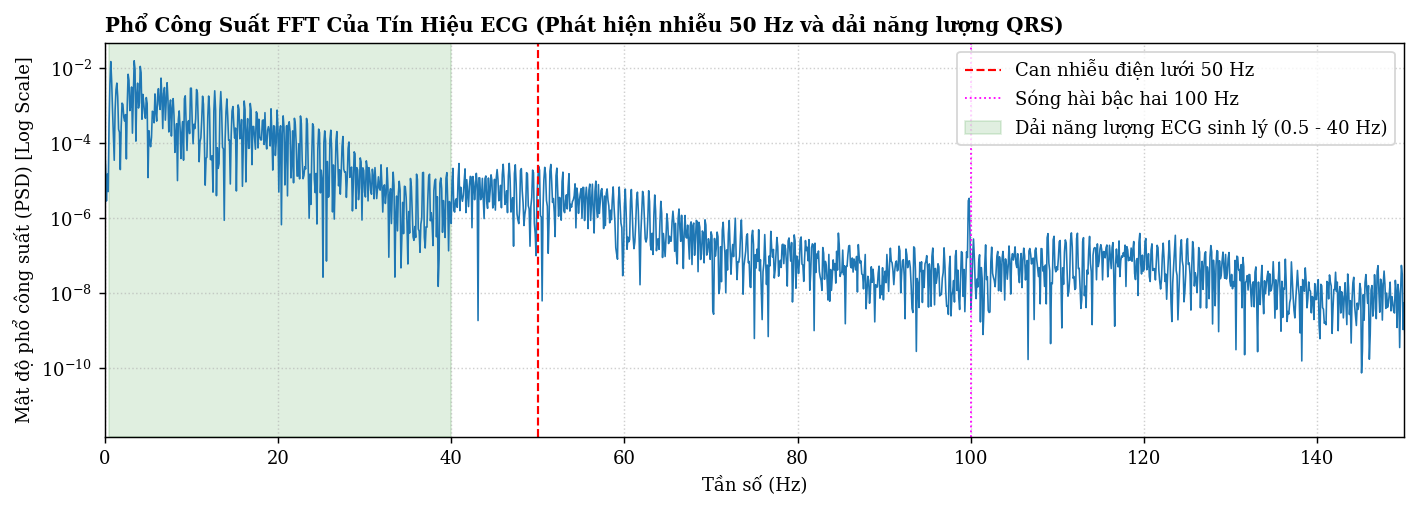

=> Năng lượng đỉnh 50 Hz: 1.0870e-05 (Chiếm tỷ lệ đáng kể trong dải tần số cao ngoài dải sinh lý)


In [4]:
N_ecg = len(ecg_seg)
ecg_detrend = ecg_seg - np.mean(ecg_seg)
fft_ecg = np.fft.rfft(ecg_detrend * signal.windows.hann(N_ecg))
freqs_ecg = np.fft.rfftfreq(N_ecg, d=1.0/fs_chest)
psd_ecg = (2.0 / (fs_chest * N_ecg)) * (np.abs(fft_ecg)**2)

plt.figure(figsize=(11, 4))
plt.semilogy(freqs_ecg, psd_ecg, color='#1f77b4', lw=0.9)
plt.axvline(50.0, color='red', linestyle='--', lw=1.2, label='Can nhiễu điện lưới 50 Hz')
plt.axvline(100.0, color='magenta', linestyle=':', lw=1.0, label='Sóng hài bậc hai 100 Hz')
plt.axvspan(0.5, 40.0, color='green', alpha=0.12, label='Dải năng lượng ECG sinh lý (0.5 - 40 Hz)')

plt.xlim([0, 150])
plt.xlabel('Tần số (Hz)')
plt.ylabel('Mật độ phổ công suất (PSD) [Log Scale]')
plt.title('Phổ Công Suất FFT Của Tín Hiệu ECG (Phát hiện nhiễu 50 Hz và dải năng lượng QRS)', loc='left')
plt.legend(loc='upper right')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

# Đánh giá tỷ lệ công suất tại 50 Hz
idx_50 = np.argmin(np.abs(freqs_ecg - 50.0))
p_50 = psd_ecg[idx_50]
p_total = np.sum(psd_ecg)
print(f"=> Năng lượng đỉnh 50 Hz: {p_50:.4e} (Chiếm tỷ lệ đáng kể trong dải tần số cao ngoài dải sinh lý)")


## Kết Luận Notebook 1:
- **Ưu điểm của FFT:** Tốc độ tính toán siêu nhanh, xác định chính xác các thành phần điều hòa tĩnh như can nhiễu 50 Hz và đỉnh nhịp tim trung bình trong cửa sổ.
- **Hạn chế cốt lõi:** Không có khả năng định vị thời gian (*time-localization*). Nếu có biến cố đột ngột (loạn nhịp, co cơ ngắn), FFT không thể chỉ ra thời điểm xảy ra biến cố.
